## Дерево решения (теория)

Деревья решений (Decision Trees) — это один из популярных методов машинного обучения, используемый как для задач классификации, так и для регрессии. Он представляет собой иерархическую структуру, где на каждом узле выполняется проверка условия, а затем происходит разветвление в зависимости от результата проверки.

Основные понятия метода:

Корневой узел (Root Node) — это начальная точка дерева, с которой начинается процесс принятия решений.
Внутренние узлы (Internal Nodes) — это промежуточные узлы, содержащие условия для разбиения данных.
Листовые узлы (Leaf Nodes) — это конечные узлы, представляющие итоговое решение (класс или числовое значение).
Глубина дерева (Tree Depth) — это количество уровней в дереве, определяющее его сложность и способность к обобщению.
Деревья решения основаны на известной структуре данных — деревьях, которые по сути представляют собой последовательные инструкции с условиями.

Например, в задаче согласования кредита может быть следующий алгоритм принятия решения:

Старше ли клиент 18 лет? Если да, то продолжаем, иначе отказываем в кредите.
Превышает ли его заработок 50 тысяч рублей? Если да, то продолжаем, иначе отказываем в кредите.
Были ли у клиента просроченные кредиты ранее? Если да, отказываем в кредите, иначе выдаем.
В листьях (терминальных, конечных узлах или конечных вершинах) деревьев стоят значения целевой функции (прогноз), а в узлах — условия перехода, определяющие, по какому из ребер идти.

Если речь идет о бинарных деревьях (каждый узел производит ветвление на две части), обычно, если условие в узле истинно, то происходит переход по левому ребру, если ложно, то по правому.

Пример построенного вручную дерева:

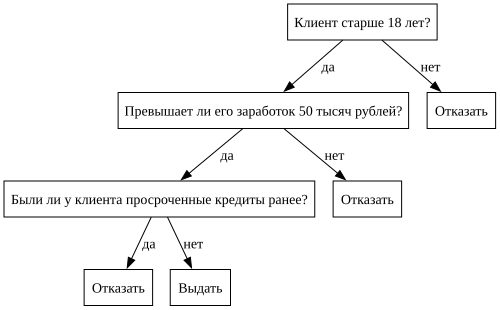

In [1]:
# визуализировать дерево можно посредством библиотеки python-graphviz
from graphviz import Digraph
dot = Digraph(node_attr={'shape': 'box'})

dot.node('A', label='Клиент старше 18 лет?')
dot.node('B', label='Превышает ли его заработок 50 тысяч рублей?')
dot.node('C', label='Отказать')
dot.node('D', label='Были ли у клиента просроченные кредиты ранее?')
dot.node('E', label='Отказать')
dot.node('F', label='Отказать')
dot.node('G', label='Выдать')

dot.edge('A', 'B', label='да')
dot.edge('A', 'C', label='нет')
dot.edge('B', 'D', label='да')
dot.edge('B', 'E', label='нет')
dot.edge('D', 'F', label='да')
dot.edge('D', 'G', label='нет')

dot

В задачах машинного обучения чаще всего в вершинах прописываются максимально простые условия. Обычно это сравнение значения одного из признаков x^j с некоторым заданным порогом t:

$[x^{j} \leq t]$

Если выполняется задача классификации, конечным прогнозом считается класс или распределение вероятностей классов. В случае регрессии прогноз в листе представляет собой вещественное число.

Большим плюсом деревьев считается тот факт, что они легко интерпретируются. То есть вы всегда можете восстановить всю цепочку принятия решения алгоритмом в отличие от любых более сложных методов — например, нейронных сетей.

Главное отрицательное качество деревьев решения — они очень легко переобучаются. Легко построить дерево, где каждый лист будет соответствовать одному объекту обучающей выборки (то есть у каждого объекта свой путь в дереве), такую структуру невозможно обобщить. Оно будет идеально подогнано под обучающую выборку, давать стопроцентный ответ на ней, но при этом не станет восстанавливать оригинальных закономерностей, и качество ответов на новых данных окажется неудовлетворительным.

## Теория построения дерева решения
В машинном обучении деревья строятся от корня к листьям. Сначала выбирается корень и критерий, по которому выборка разбивается пополам (или на несколько частей). Затем то же самое делается для каждого из потомков этого корня и так далее до остановки.

Задача на каждом этапе состоит в выборе способа разбиения каждого узла, то есть в выборе значения порога, с которым будет сравниваться значение одного из признаков в каждом узле.

Разбиение происходит на основании заранее заданного функционала качества Q(X,j,t). Находятся наилучшие значения j (признак) и t (порог) для выбора порога $[x^{j}<t]$. Параметры j и t можно выбирать перебором: признаков конечное число, а из всех возможных значений порога t можно рассматривать только те, при которых получаются различные разбиения на две подвыборки.

Таким образом, различных значений параметра t будет столько же, сколько различных значений признака x^j в обучающей выборке.

В каждой потенциальной вершине производится проверка, не выполняется ли некоторое условие останова. Если оно выполняется, разбиение прекращается, такая вершина будет содержать прогноз.

В задаче классификации это будет класс, к которому относится большая часть объектов из выборки в листе Xm.

$a_{m} = \text{argmax}_{y \in Y} \sum_{i \in X_{m}}[y_{i}=y]$

Или доля объектов определенного класса k, если требуется предсказать вероятности классов:

$a_{mk} = \frac{1}{|X_{m}|} \sum_{i \in X_{m}}[y_{i}=k]$

В случае регрессии в качестве ответа можно давать средние значение по выборке по выборке в листе:

$a_{m} = \frac{1}{|X_{m}|} \sum_{i \in X_{m}}y_{i}$

За функционал качества при работе с деревом решений принимается функционал вида:

$Q(X_{m}, j, t) = H(X_{m}) - \frac{|X_{l}|}{|X_{m}|}H(X_{l}) - \frac{|X_{r}|}{|X_{m}|}H(X_{r})$

где:

 Xm — множество объектов, попавших в лист на этом шаге,
 Xl и Xr — множества, попадающие в левое и правое поддерево, соответственно, после гипотетического разбиения.
 H(X) — критерий информативности. Он оценивает качество распределения объектов в подмножестве и тем меньше, чем меньше разнообразие ответов в X. Соответственно, задача обучения состоит в его минимизации и максимизации Q(Xm,j,t) на этом шаге.

## Критерий информативности
В случае регрессии разброс будет характеризоваться дисперсией, поэтому критерий информативности будет записан в виде:

$H(X) = \frac{1}{X}\sum_{i\in X}(y_{i} - \bar{y}(X))^{2}$

В задаче классификации есть несколько способов определить критерий информативности.

Обозначим через  Pk долю объектов класса k  в выборке X :

$p_{k} = \frac{1}{|X|}\sum_{i\in X}[y_{i} = k]$

Pk будет характеризовать вероятность выдачи класса .

Критерий Джини, или индекс Джини, выглядит следующим образом:

$H(X) = \sum^{K}_{k=1}p_{k}(1-p_{k})$

где K  — количество классов в наборе данных X.

Его минимум достигается, когда все объекты в подмножестве относятся к одному классу, а максимум — при равном содержании объектов всех классов. Критерий информативности Джини можно интерпретировать как вероятность ошибки случайного классификатора.
Еще один критерий информативности — энтропийный критерий. Он также называется энтропией Шеннона и записывается как:

$H(X) = - \sum^{K}_{k=1}p_{k}\text{log}_{2}p_{k}$

Минимум энтропии также достигается, когда все объекты относятся к одному классу, а максимум — при равномерном распределении. Прирост информации есть утрата неопределенности (=уменьшение энтропии). В формуле полагается, что $0\text{log}_{2}0=0$.

## Остановка построения дерева
Критерии останова — это критерий, который показывает, надо ли остановить процесс построения дерева. Правильный выбор критериев останова, относящихся к росту дерева, может существенно повлиять на его качество.
Существует множество возможных ограничений:

Ограничение максимальной глубины дерева.
Этот критерий считается довольно грубым, но хорошо зарекомендовавшим себя в построении композиций деревьев — когда несколько деревьев объединяются в один алгоритм.
Ограничение максимального количества листьев.
Ограничение минимального количества  объектов в листе.
Оно должно быть достаточным, чтобы построить надежный прогноз.
Останов, когда все объекты в листе относятся к одному классу.
Требование улучшения функционала качества при разбиении на какую-то минимальную величину.
Преимущества и недостатки
Преимущества:

Простота интерпретации и визуализации.
Не требует масштабирования данных.
Может работать как с числовыми, так и категориальными признаками.
Недостатки:

Склонность к переобучению (если дерево слишком глубокое).
Нестабильность (небольшие изменения в данных могут привести к значительному изменению структуры дерева).
Менее точны по сравнению с ансамблевыми методами (например, случайный лес или градиентный бустинг).